In [ ]:
!pip install -q kaggle

In [ ]:
import os

os.listdir("/content")

['.config', 'sample_data']

In [ ]:
import kagglehub #Downloading dataset from kaggle

# Download latest version
path = kagglehub.dataset_download("puneet6060/intel-image-classification")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Path to dataset files: /kaggle/input/intel-image-classification


In [ ]:
os.listdir(path)

['seg_train', 'seg_pred', 'seg_test']

In [ ]:
train_path = os.path.join(path, "seg_train", "seg_train") #setting the path of the training and testing data
test_path = os.path.join(path, "seg_test", "seg_test")

In [ ]:
print("Train classes:", os.listdir(train_path)) #Checking and confirmig the classes
print("Test classes:", os.listdir(test_path))

Train classes: ['mountain', 'street', 'buildings', 'sea', 'forest', 'glacier']
Test classes: ['mountain', 'street', 'buildings', 'sea', 'forest', 'glacier']


In [ ]:
from PIL import Image #Checking sample image from the training data

sample_class = os.listdir(train_path)[0]
sample_folder = os.path.join(train_path, sample_class)

sample_image = os.listdir(sample_folder)[0]
image_path = os.path.join(sample_folder, sample_image)

img = Image.open(image_path)

print("Class:", sample_class)
print("Image size:", img.size)
print("Image mode:", img.mode)

Class: mountain
Image size: (150, 150)
Image mode: RGB


In [ ]:
import tensorflow as tf

train = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(150, 150),
    batch_size=32
)

test = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(150, 150),
    batch_size=32
)

Found 14034 files belonging to 6 classes.
Found 3000 files belonging to 6 classes.


In [ ]:
class_names = train.class_names

print(class_names)

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


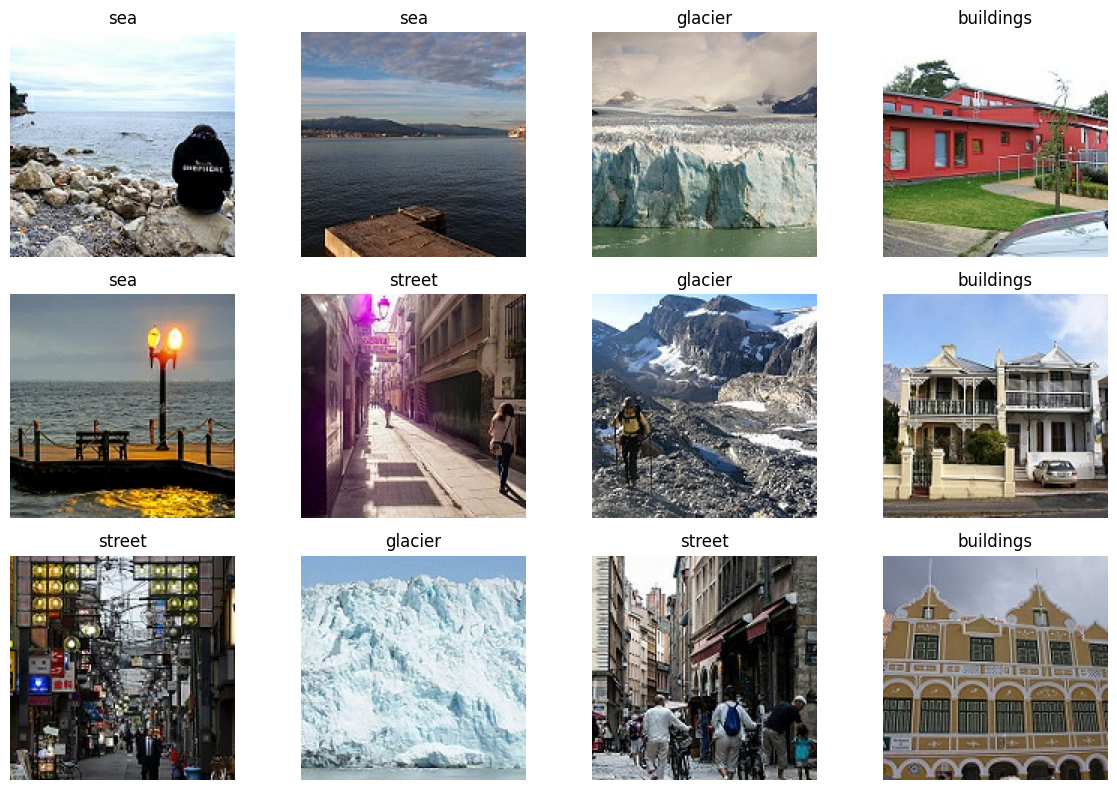

In [ ]:
plt.figure(figsize=(12, 8)) #plotting images from the training class

for images, labels in train.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
image_size=(150, 150) #resizing imge to 150x15p0 px

In [ ]:
train = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(150, 150),
    batch_size=32
)

val = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(150, 150),
    batch_size=32
) #creating validation data from training data

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.


In [ ]:
print(train.class_names)
print(val.class_names)
print(test.class_names)

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [ ]:
normalization = tf.keras.layers.Rescaling(1./255)

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"), #flipping each image horizontally
    tf.keras.layers.RandomRotation(0.1), #roation
    tf.keras.layers.RandomZoom(0.1), #Zooming
    tf.keras.layers.RandomTranslation(0.1, 0.1) #Translating
])

In [39]:
model = tf.keras.Sequential([  #Creating the model 4 layers
    tf.keras.layers.Input(shape=(150, 150, 3)),

    normalization, #applying the normalization for all images
    data_augmentation, #appying augmentation for each image

    tf.keras.layers.Conv2D(32, (3,3), activation="relu"),
    tf.keras.layers.MaxPooling2D(), #layer1

    tf.keras.layers.Conv2D(64, (3,3), activation="relu"),
    tf.keras.layers.MaxPooling2D(), #layer2

    tf.keras.layers.Conv2D(128, (3,3), activation="relu"),
    tf.keras.layers.MaxPooling2D(), #layer3

    tf.keras.layers.Conv2D(256, (3,3), activation="relu"),
    tf.keras.layers.MaxPooling2D(), #layer4

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(6, activation="softmax") #using softmax function since its a multiclass problem
])

In [40]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 15, 15, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,086 (1.61 MB)

 Trainable params: 422,086 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [41]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
) #compiling the model

In [42]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
) #seting the early stop variable with respect to the validation loss

In [44]:
history = model.fit(
    train,
    validation_data=val,
    epochs=30,
    callbacks=[early_stop]
) #Training the model

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.8481 - loss: 0.4331 - val_accuracy: 0.7887 - val_loss: 0.6228
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.8484 - loss: 0.4302 - val_accuracy: 0.8532 - val_loss: 0.4184
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.8509 - loss: 0.4216 - val_accuracy: 0.7790 - val_loss: 0.6805
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.8587 - loss: 0.4047 - val_accuracy: 0.8150 - val_loss: 0.5548
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.8499 - loss: 0.4110 - val_accuracy: 0.7641 - val_loss: 0.7728
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.8536 - loss: 0.4057 - val_accuracy: 0.8325 - val_loss: 0.4885
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.8559 - loss: 0.3924 - val_accuracy: 0.8150 - val_loss: 0.5396
Epoch 8/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.8587 - loss: 0.3882 - 

In [45]:
test_loss, test_accuracy = model.evaluate(test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.8467 - loss: 0.4302
Test Loss: 0.4301784336566925
Test Accuracy: 0.846666693687439


In [46]:
import numpy as np
from sklearn.metrics import classification_report

y_true = np.concatenate([y.numpy() for x, y in test])

y_prob = model.predict(test)

y_pred = np.argmax(y_prob, axis=1)

94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step


In [47]:
class_names = test.class_names

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

   buildings       0.75      0.89      0.81       437
      forest       0.97      0.97      0.97       474
     glacier       0.83      0.77      0.80       553
    mountain       0.81      0.76      0.78       525
         sea       0.85      0.84      0.85       510
      street       0.88      0.87      0.88       501

    accuracy                           0.85      3000
   macro avg       0.85      0.85      0.85      3000
weighted avg       0.85      0.85      0.85      3000



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


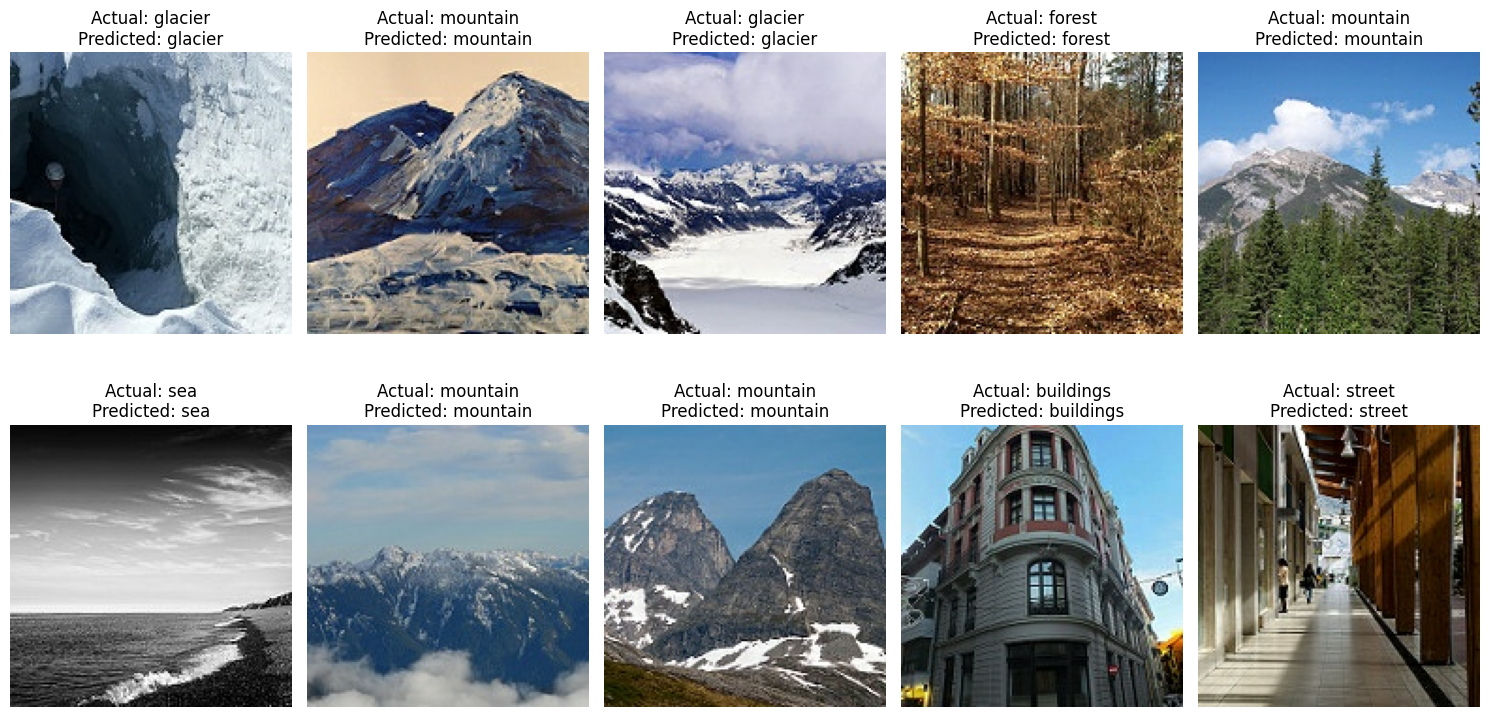

In [49]:
import numpy as np
import matplotlib.pyplot as plt

# Take all test images and labels
all_images = []
all_labels = []

for images, labels in test:
    all_images.append(images.numpy())
    all_labels.append(labels.numpy())

all_images = np.concatenate(all_images)
all_labels = np.concatenate(all_labels)

#indices = np.random.choice(len(all_images), 10, replace=False)
indices = np.random.choice(len(all_images), 10, replace=False)
# Predict
predictions = model.predict(all_images[indices])
predicted_labels = np.argmax(predictions, axis=1)

# Class names
class_names = test.class_names

# Display
plt.figure(figsize=(15, 8))

for i, idx in enumerate(indices):
    plt.subplot(2, 5, i + 1)

    plt.imshow(all_images[idx].astype("uint8"))

    actual = class_names[all_labels[idx]]
    predicted = class_names[predicted_labels[i]]

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [50]:
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np

img = load_img("/content/test_image_forest.png", target_size=(150, 150))

img_array = img_to_array(img)

img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

predicted_class = np.argmax(prediction[0])

print("Predicted class:", test.class_names[predicted_class]) #predicted correctly

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/step
Predicted class: forest


In [ ]:
#from the traing its obtained that the model has obtained an accuracy of  0.84666669 with the CNN model created.